# 03 — аналіз SSL-претренування ViT-S/16 (MAE + InfoNCE)

Ноутбук лише читає артефакти: `runs/ssl_*/` (`metrics.csv`, `config.yaml`, `recon/*.png`), `reports/tables/probe_<tag>.json` та `runs/probe/<tag>/features_val.pt`, і будує графіки функціями з `malaria_ssl.ssl.viz`. Probe: fit на train-кропах, оцінка на val-кропах; test не використовується.

Поки повних запусків немає, показуються dry runs (`dry_b_*` — 2 епохи по 25 кроків кожного режиму, `dry_a_overfit_mae64` — overfit MAE). Це перевірка пайплайну, а не результати.

Як отримати артефакти:
```
python scripts/pretrain.py --config configs/ssl/joint.yaml
python scripts/probe.py --run runs/ssl_joint
python scripts/probe.py --ref random
python scripts/probe.py --ref imagenet
```

In [1]:
import pandas as pd

from malaria_ssl.ssl import viz
from malaria_ssl.utils.config import resolve_path

pd.set_option('display.precision', 3)
runs = viz.find_ssl_runs('ssl_')
FALLBACK = not runs  # until the real runs exist: short smokes of the three modes
if FALLBACK:
    runs = [viz.load_ssl_run(resolve_path('runs') / n) for n in ('dry_b_joint', 'dry_b_mae_only', 'dry_b_con_only')]
overfit = viz.find_ssl_runs('dry_a_overfit_mae')
probes = viz.load_probes()
print('FALLBACK (dry runs only):', FALLBACK)
print('runs:', [r['name'] for r in runs])
print('probes:', [p['tag'] for p in probes])

C:\Users\Alex\miniconda3\envs\medthesis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


FALLBACK (dry runs only): False
runs: ['ssl_sweep_lc005', 'ssl_sweep_lc02', 'ssl_sweep_lc10', 'ssl_sweep_lr5e4', 'ssl_sweep_uncertainty']
probes: ['ref_imagenet', 'ref_random_init', 'ssl_sweep_lc005', 'ssl_sweep_lc02', 'ssl_sweep_lc10', 'ssl_sweep_lr5e4', 'ssl_sweep_uncertainty']


## Криві втрат

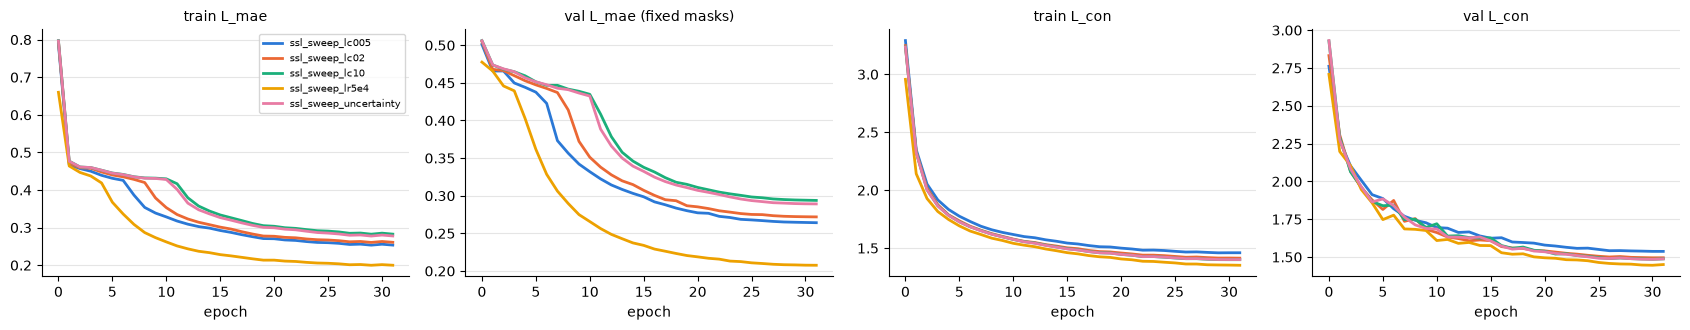

In [2]:
viz.plot_losses(runs);

## Ефективні ваги, learning rate, норма градієнта

Для `uncertainty` ваги = exp(−s_i); для `fixed` — λ з конфігу.

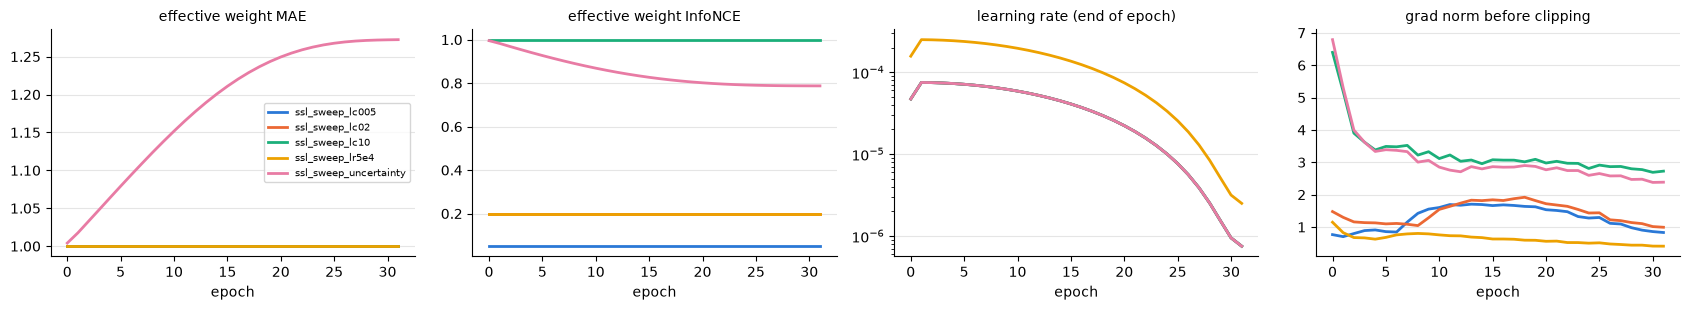

In [3]:
viz.plot_weights_lr(runs);

## Діагностика колапсу (фіксовані val-пари)

`std × √d` ≈ 1 — ембединги розкидані по сфері, → 0 — повний колапс; effective rank ловить розмірнісний колапс.

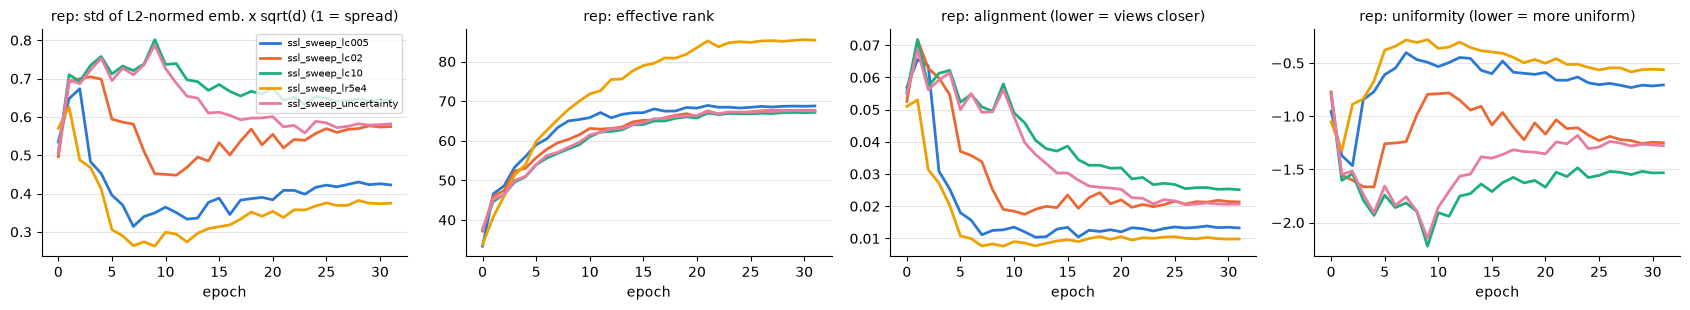

In [4]:
viz.plot_collapse(runs, 'rep');

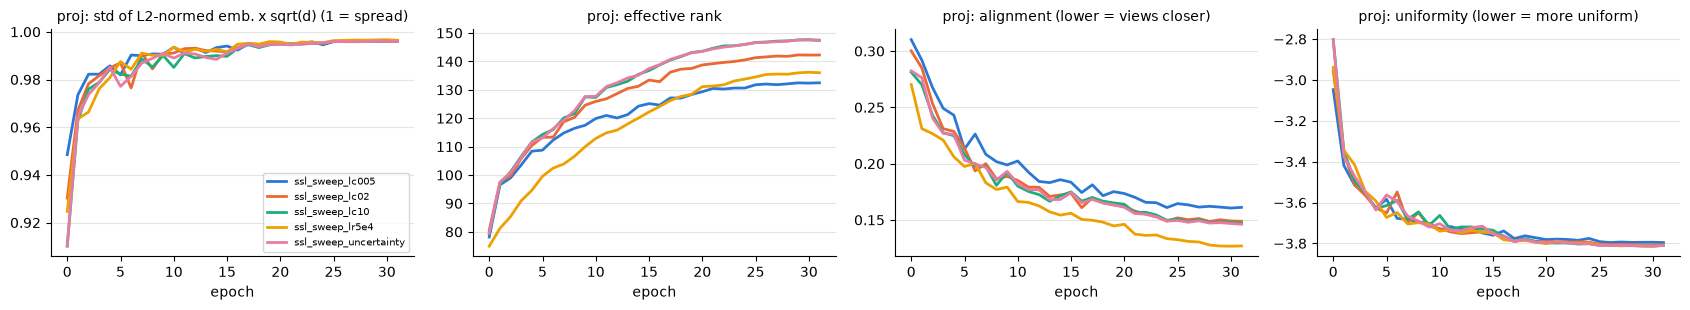

In [5]:
viz.plot_collapse([r for r in runs if 'proj/erank' in r['history']], 'proj');

## Light probe під час тренування

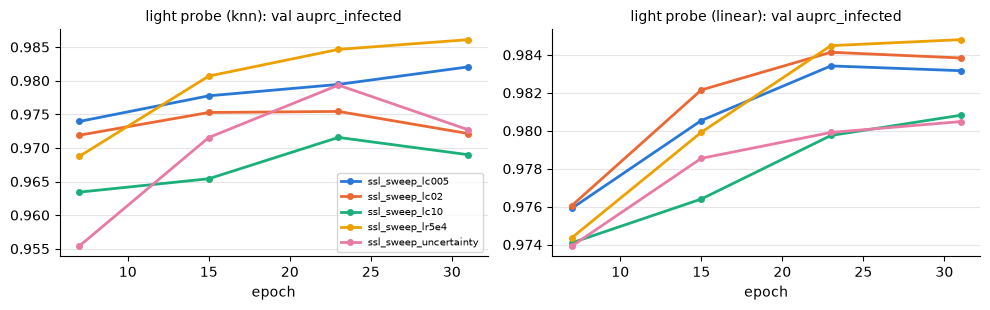

In [6]:
viz.plot_light_probe(runs, 'auprc_infected');

## Реконструкції MAE (рядки: оригінал | маска | реконструкція)

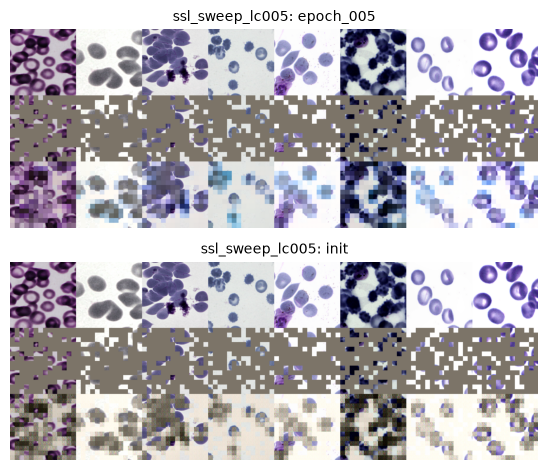

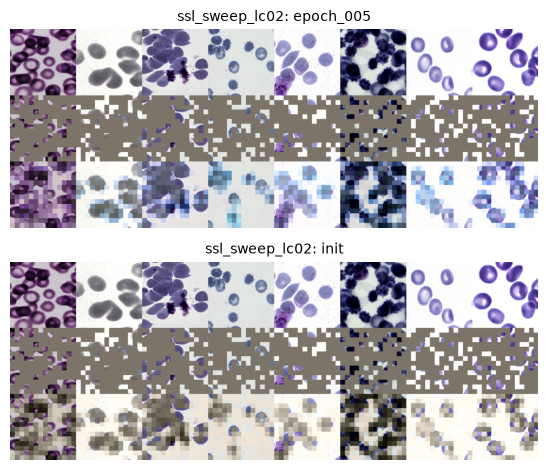

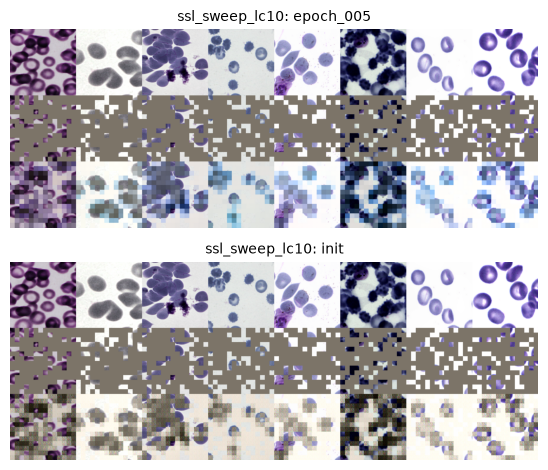

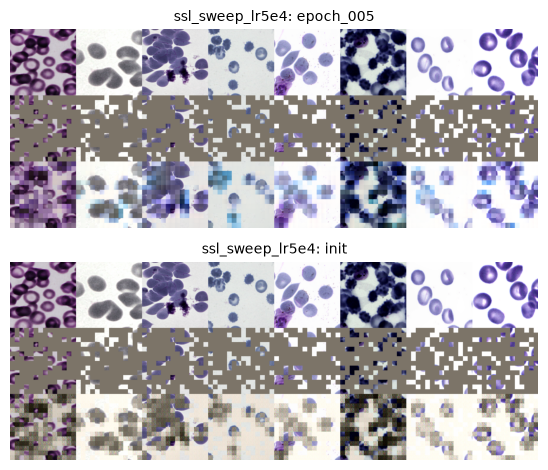

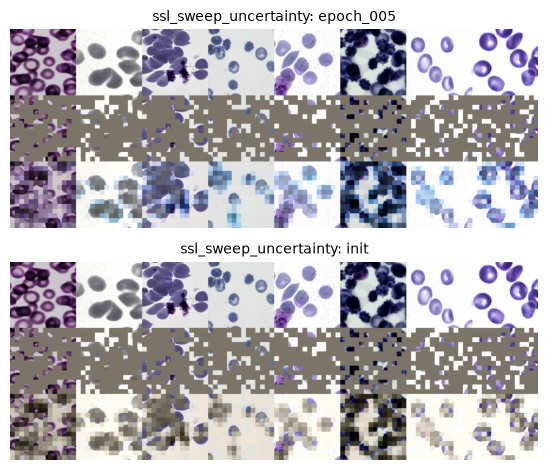

In [7]:
for r in runs:
    if r['recon']:
        viz.show_recon(r, (0, -1))

### Dry run (a): overfit MAE на 64 фіксованих train-кропах (без аугментацій)

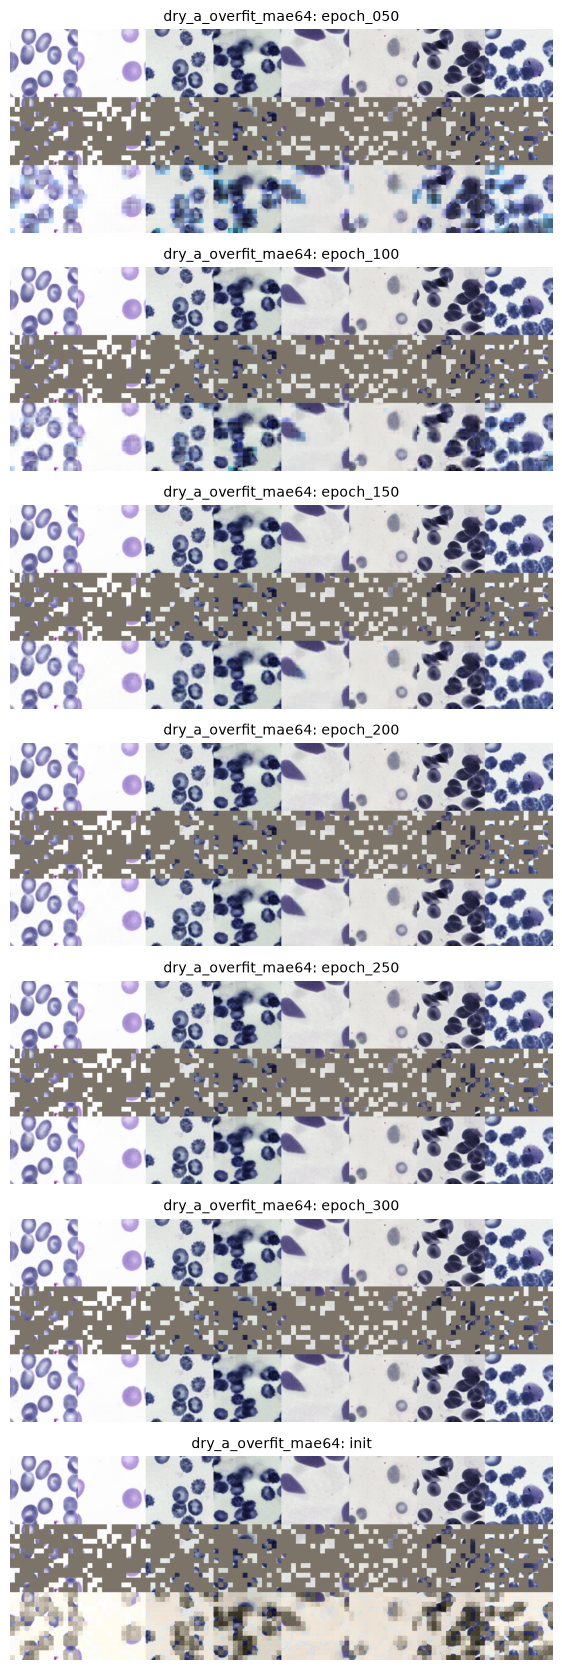

In [8]:
for r in overfit:
    viz.show_recon(r, tuple(range(len(r['recon']))))

## Probe: усі енкодери та референси (val-кропи, 100% міток, 95% bootstrap CI по зображеннях)

In [9]:
viz.probe_table(probes)

,encoder,method,auroc_infected,auroc_infected_CI95,auprc_infected,auprc_infected_CI95,balanced_acc,balanced_acc_CI95,macro_f1,macro_f1_CI95
0,ref_imagenet,knn,0.993,"[0.986, 0.997]",0.971,"[0.952, 0.985]",0.616,"[0.546, 0.686]",0.683,"[0.602, 0.746]"
1,ref_imagenet,linear,0.997,"[0.995, 0.998]",0.981,"[0.972, 0.989]",0.736,"[0.676, 0.797]",0.646,"[0.589, 0.696]"
2,ref_random_init,knn,0.928,"[0.908, 0.944]",0.730,"[0.660, 0.787]",0.437,"[0.371, 0.508]",0.465,"[0.384, 0.536]"
3,ref_random_init,linear,0.986,"[0.980, 0.991]",0.924,"[0.883, 0.954]",0.702,"[0.630, 0.765]",0.515,"[0.460, 0.567]"
4,ssl_sweep_lc005,knn,0.996,"[0.991, 0.999]",0.982,"[0.967, 0.993]",0.639,"[0.571, 0.708]",0.689,"[0.618, 0.750]"
5,ssl_sweep_lc005,linear,0.996,"[0.989, 0.999]",0.983,"[0.967, 0.995]",0.837,"[0.785, 0.884]",0.692,"[0.638, 0.738]"
6,ssl_sweep_lc02,knn,0.996,"[0.990, 0.999]",0.972,"[0.951, 0.989]",0.682,"[0.614, 0.750]",0.724,"[0.652, 0.784]"
7,ssl_sweep_lc02,linear,0.996,"[0.991, 0.999]",0.984,"[0.968, 0.995]",0.817,"[0.758, 0.868]",0.670,"[0.612, 0.721]"
8,ssl_sweep_lc10,knn,0.995,"[0.990, 0.999]",0.969,"[0.943, 0.989]",0.692,"[0.622, 0.761]",0.726,"[0.658, 0.781]"
9,ssl_sweep_lc10,linear,0.995,"[0.989, 0.999]",0.981,"[0.964, 0.993]",0.839,"[0.784, 0.885]",0.691,"[0.638, 0.740]"


## Stain-shifted probe

Ті самі класифікатори (fit на ЧИСТИХ train-кропах) оцінюються на val-кропах після фіксованого seeded фотометричного зсуву: HED (σ 0.08), яскравість/контраст/насиченість ±0.3, hue ±0.05, легке розмиття, JPEG 30–60 (`probe.stain_shift` у `configs/ssl/probe.yaml`). Зсув один на зображення, test не використовується. Зсув сильніший за SSL-аугментації, але SSL їх бачив — це тест інваріантності, а не відтворення test-домену.

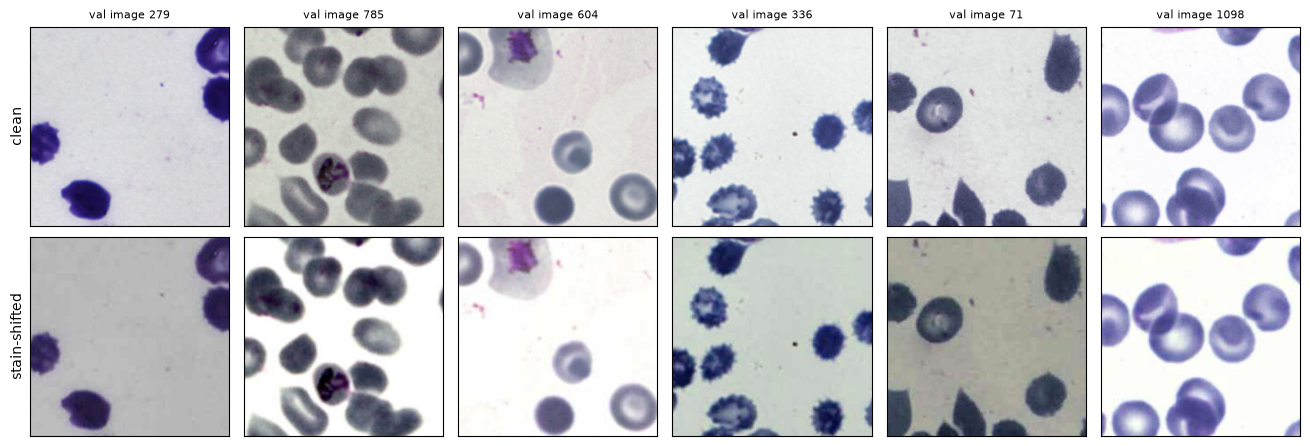

In [10]:
viz.show_stain_shift();

In [11]:
viz.stain_table(probes)

,encoder,method,auprc_infected_clean,auprc_infected_clean_CI95,auprc_infected_stain,auprc_infected_stain_CI95,auprc_infected_drop,macro_f1_clean,macro_f1_clean_CI95,macro_f1_stain,macro_f1_stain_CI95,macro_f1_drop
0,ref_imagenet,knn,0.971,"[0.952, 0.985]",0.905,"[0.874, 0.932]",0.066,0.683,"[0.602, 0.746]",0.535,"[0.455, 0.602]",0.148
1,ref_imagenet,linear,0.981,"[0.972, 0.989]",0.943,"[0.921, 0.961]",0.039,0.646,"[0.589, 0.696]",0.530,"[0.471, 0.586]",0.116
2,ref_random_init,knn,0.730,"[0.660, 0.787]",0.364,"[0.302, 0.437]",0.366,0.465,"[0.384, 0.536]",0.294,"[0.244, 0.344]",0.171
3,ref_random_init,linear,0.924,"[0.883, 0.954]",0.525,"[0.421, 0.638]",0.399,0.515,"[0.460, 0.567]",0.294,"[0.256, 0.336]",0.221
4,ssl_sweep_lc005,knn,0.982,"[0.967, 0.993]",0.966,"[0.941, 0.984]",0.016,0.689,"[0.618, 0.750]",0.640,"[0.567, 0.700]",0.049
5,ssl_sweep_lc005,linear,0.983,"[0.967, 0.995]",0.968,"[0.949, 0.982]",0.015,0.692,"[0.638, 0.738]",0.579,"[0.525, 0.629]",0.113
6,ssl_sweep_lc02,knn,0.972,"[0.951, 0.989]",0.975,"[0.954, 0.989]",-0.003,0.724,"[0.652, 0.784]",0.672,"[0.601, 0.727]",0.052
7,ssl_sweep_lc02,linear,0.984,"[0.968, 0.995]",0.974,"[0.956, 0.987]",0.010,0.670,"[0.612, 0.721]",0.601,"[0.544, 0.655]",0.069
8,ssl_sweep_lc10,knn,0.969,"[0.943, 0.989]",0.972,"[0.950, 0.988]",-0.003,0.726,"[0.658, 0.781]",0.690,"[0.615, 0.747]",0.036
9,ssl_sweep_lc10,linear,0.981,"[0.964, 0.993]",0.963,"[0.936, 0.983]",0.018,0.691,"[0.638, 0.740]",0.615,"[0.561, 0.667]",0.076


## Вибір λ (sweep)

Порядок: linear AUPRC infected (чисті val) → stain-shifted linear AUPRC → linear AUPRC при 10% міток → linear macro-F1. Нічия = значення в межах інтервалу лідера (95% CI; для 10% — mean − std по seeds).

In [12]:
sweep = [p for p in probes if p['tag'].startswith('ssl_sweep_')]
if sweep:
    table, sel = viz.selection_table(sweep)
    print('winner:', sel['winner'])
    for s in sel['steps']:
        print(f"  {s['criterion']}: leader {s['leader']}, tied {s['tied']}")
    display(table)
else:
    print('no sweep probes yet (reports/tables/probe_ssl_sweep_*.json)')

winner: ssl_sweep_lc005
  auprc_clean: leader ssl_sweep_lr5e4, tied ['ssl_sweep_lc005', 'ssl_sweep_lc02', 'ssl_sweep_lc10', 'ssl_sweep_lr5e4', 'ssl_sweep_uncertainty']
  auprc_stain: leader ssl_sweep_lc02, tied ['ssl_sweep_lc005', 'ssl_sweep_lc02', 'ssl_sweep_lc10', 'ssl_sweep_lr5e4', 'ssl_sweep_uncertainty']
  auprc_10pct: leader ssl_sweep_lc005, tied ['ssl_sweep_lc005']


,auprc_clean,auprc_stain,auprc_10pct,macro_f1,winner
ssl_sweep_lc005,0.983,0.968,0.966,0.692,True
ssl_sweep_lc02,0.984,0.974,0.961,0.670,False
ssl_sweep_lc10,0.981,0.963,0.952,0.691,False
ssl_sweep_lr5e4,0.985,0.973,0.958,0.712,False
ssl_sweep_uncertainty,0.980,0.963,0.952,0.699,False


## Recall по класах (linear probe)

In [13]:
viz.per_class_recall_table(probes, 'linear')

,encoder,class,n_val,recall,CI95
0,ref_imagenet,red blood cell,2000,0.963,"[0.953, 0.972]"
1,ref_imagenet,leukocyte,14,0.929,"[0.778, 1.000]"
2,ref_imagenet,gametocyte,20,0.550,"[0.333, 0.769]"
3,ref_imagenet,ring,49,0.735,"[0.581, 0.862]"
4,ref_imagenet,trophozoite,204,0.721,"[0.650, 0.788]"
5,ref_imagenet,schizont,25,0.520,"[0.320, 0.710]"
6,ref_random_init,red blood cell,2000,0.910,"[0.885, 0.931]"
7,ref_random_init,leukocyte,14,0.643,"[0.368, 0.900]"
8,ref_random_init,gametocyte,20,0.700,"[0.500, 0.895]"
9,ref_random_init,ring,49,0.878,"[0.763, 0.961]"


## Low-label: 1% / 10% / 100% міток train-кропів

,encoder,method,fraction,mean,std,n_train
1,ref_imagenet,knn,0.01,0.888,0.021,60.0
2,ref_imagenet,knn,0.10,0.941,0.006,593.0
0,ref_imagenet,knn,1.00,0.971,0.000,NaN
4,ref_imagenet,linear,0.01,0.914,0.013,60.0
5,ref_imagenet,linear,0.10,0.978,0.004,593.0
3,ref_imagenet,linear,1.00,0.981,0.000,NaN
7,ref_random_init,knn,0.01,0.276,0.026,60.0
8,ref_random_init,knn,0.10,0.486,0.011,593.0
6,ref_random_init,knn,1.00,0.730,0.000,NaN
10,ref_random_init,linear,0.01,0.483,0.100,60.0


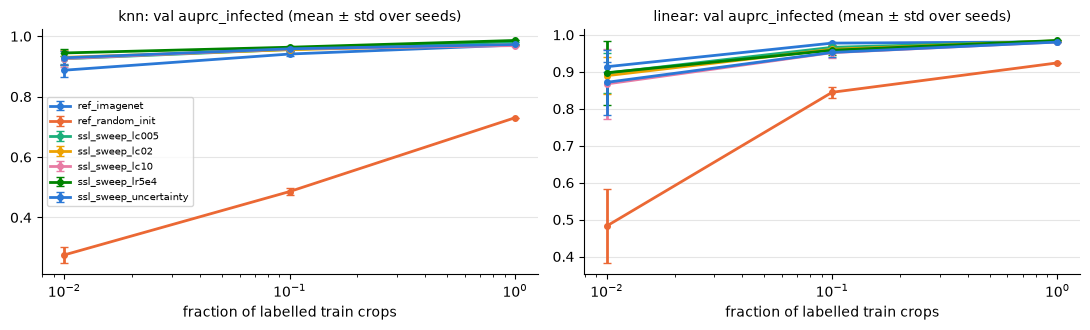

In [14]:
viz.plot_low_label(probes, 'auprc_infected');
viz.low_label_table(probes, 'auprc_infected')

## PCA ембедингів клітин (val), кольори — класи

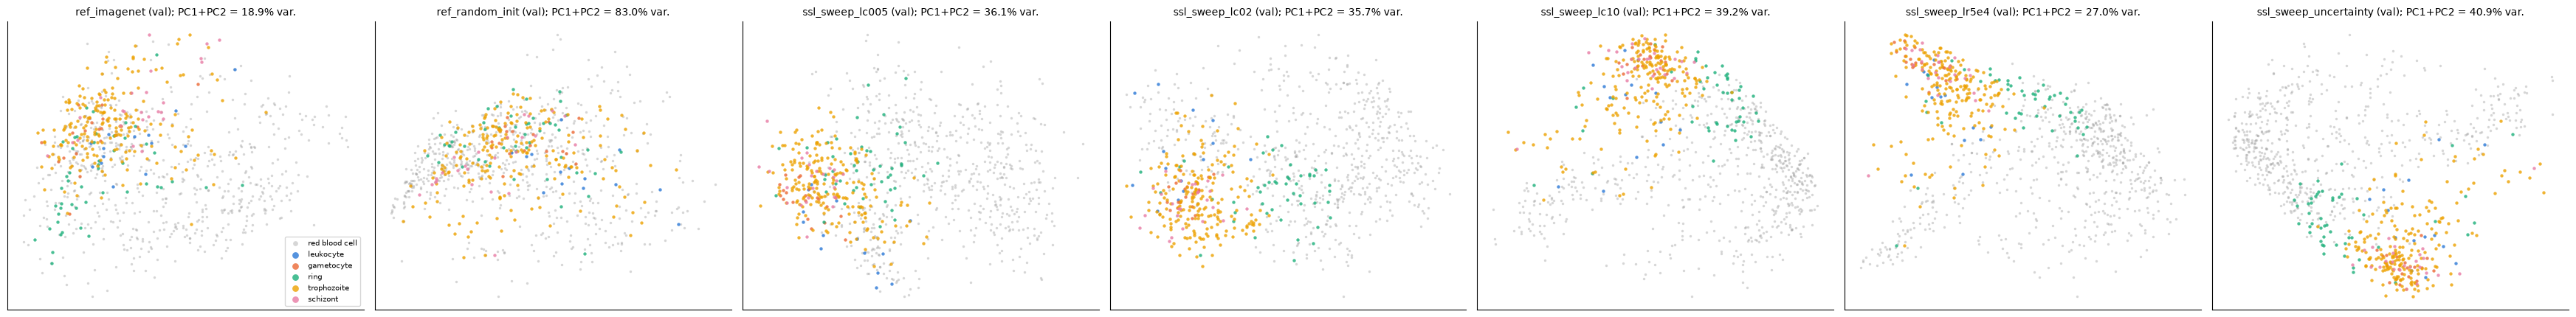

In [15]:
viz.plot_pca([p['tag'] for p in probes], 'val');